# AQI v2 · Geospatial prediction for the New York region
## From 60 monitors to a continuous, probabilistic map of the air

*Florian Grolleau · Air Quality Index Studies, version 2*

Monitors are points; people live everywhere in between. This notebook predicts air
quality at every location of the New York tri-state region:

1. **The network** and the **spatial structure** of PM2.5 and ozone (variograms).
2. **A benchmark of spatial predictors** under leave-one-station-out validation:
   inverse distance weighting, ordinary kriging, Gaussian processes and RFSI, a
   machine-learning interpolator that learns how to combine the neighbouring monitors.
3. **Maps**: long-term exposure, the ozone/NO2 "titration" mirror, the probability of
   exceeding the WHO guideline, the worst day of the record.
4. **The June 2023 smoke plume**, hour by hour over the north-east (animation and
   interactive map).
5. **Next-day forecast maps** with uncertainty, including a live forecast.
6. **Exposure by borough**, weighted by population.

In [1]:
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import animation
from matplotlib.colors import BoundaryNorm, Normalize

sys.path.insert(0, str(Path.cwd().parent))
from aqi2 import data, features, forecasting as fc, indices as ix, spatial as sp, viz  # noqa: E402

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
viz.set_theme()
RNG = np.random.default_rng(3)

an, sites = data.load_airnow_daily()
layers = data.load_basemap()
wx = data.regional_weather(data.load_weather())
PM = data.airnow_matrix(an, "pm25", min_days=180).clip(lower=0)
O3 = data.airnow_matrix(an, "o3_8h", min_days=180).clip(lower=0)
LAST_DAY = PM.index.max()
print(f"{PM.shape[1]} PM2.5 and {O3.shape[1]} ozone monitors with at least 180 days, up to {LAST_DAY:%Y-%m-%d}")

METRO = (-75.05, -72.55, 40.15, 41.45)       # lon_min, lon_max, lat_min, lat_max of the maps
CITY = (-74.28, -73.68, 40.48, 40.93)
boroughs = layers["nyc_boroughs"]

74 PM2.5 and 68 ozone monitors with at least 180 days, up to 2026-10-23


## 1 · The monitoring network

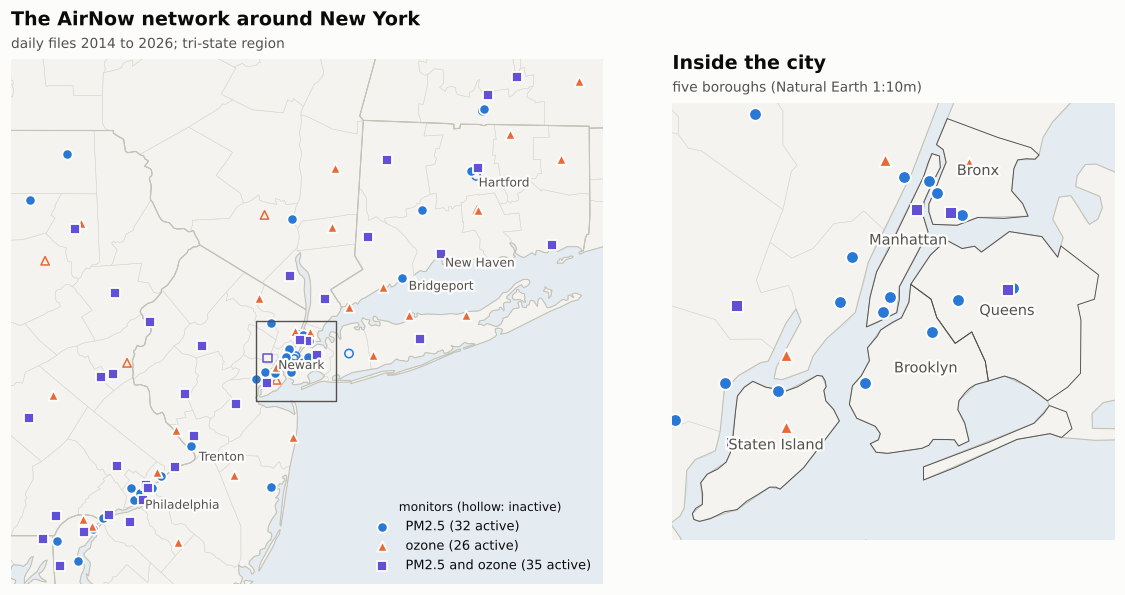

In [2]:
def station_table(M):
    s = sites.loc[M.columns, ["site", "state", "lat", "lon"]].copy()
    s["xy"] = list(sp.to_xy_km(s.lat, s.lon))
    return s


st_pm, st_o3 = station_table(PM), station_table(O3)
active_pm = PM.loc[LAST_DAY - pd.Timedelta(days=365):].notna().any()
active_o3 = O3.loc[LAST_DAY - pd.Timedelta(days=365):].notna().any()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.2), gridspec_kw={"width_ratios": [1.55, 1], "wspace": 0.04})
ax = axes[0]
viz.draw_basemap(ax, layers, extent=(-76.1, -71.7, 39.45, 42.4))
both = st_pm.index.intersection(st_o3.index)
for idx, marker, color, lab in [(st_pm.index.difference(both), "o", viz.SERIES[0], "PM2.5"),
                                (st_o3.index.difference(both), "^", viz.SERIES[1], "ozone"),
                                (both, "s", viz.SERIES[6], "PM2.5 and ozone")]:
    s = sites.loc[idx]
    act = (active_pm.reindex(idx).fillna(False) | active_o3.reindex(idx).fillna(False)).to_numpy()
    ax.scatter(s.lon[act], s.lat[act], marker=marker, s=46, color=color, edgecolor=viz.SURFACE, lw=1.2, zorder=5,
               label=f"{lab} ({act.sum()} active)")
    ax.scatter(s.lon[~act], s.lat[~act], marker=marker, s=30, facecolor="none", edgecolor=color, lw=1, zorder=4)
x0, x1, y0, y1 = CITY
ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=viz.INK_2, lw=0.9, zorder=6)
import matplotlib.patheffects as pe  # noqa: E402
HALO = [pe.withStroke(linewidth=3, foreground=viz.SURFACE)]
for lon_, lat_, name in [(-74.17, 40.735, "Newark"), (-73.20, 41.18, "Bridgeport"), (-72.93, 41.31, "New Haven"),
                         (-75.16, 39.95, "Philadelphia"), (-72.68, 41.76, "Hartford"), (-74.76, 40.22, "Trenton")]:
    ax.annotate(name, (lon_, lat_), xytext=(5, -9), textcoords="offset points", fontsize=8, color=viz.INK_2,
                zorder=9, path_effects=HALO)
ax.legend(loc="lower right", fontsize=8.5, title="monitors (hollow: inactive)", title_fontsize=8)
viz.title(ax, "The AirNow network around New York", f"daily files 2014 to {LAST_DAY:%Y}; tri-state region")
ax = axes[1]
viz.draw_basemap(ax, layers, extent=CITY, boroughs=True)
for idx, marker, color in [(st_pm.index.difference(both), "o", viz.SERIES[0]),
                           (st_o3.index.difference(both), "^", viz.SERIES[1]), (both, "s", viz.SERIES[6])]:
    s = sites.loc[idx]
    s = s[(s.lon.between(CITY[0], CITY[1])) & (s.lat.between(CITY[2], CITY[3]))]
    ax.scatter(s.lon, s.lat, marker=marker, s=70, color=color, edgecolor=viz.SURFACE, lw=1.3, zorder=7)
for _, b in boroughs.iterrows():
    c = b.geometry.representative_point()
    ax.text(c.x, c.y, b.borough, fontsize=9.5, color=viz.INK_2, ha="center", va="center", zorder=9,
            path_effects=HALO)
viz.title(ax, "Inside the city", "five boroughs (Natural Earth 1:10m)")
viz.save(fig, "03_network")
plt.show()

## 2 · How far does a measurement reach? Variograms

The semivariogram measures how different two monitors are as a function of their
distance, pooled over all days after standardising each day (so clean and polluted days
weigh the same). The range is the distance beyond which monitors stop informing each
other.

nugget           0.699
psill            0.630
range          497.319
nugget_frac      0.526
Name: pm25, dtype: float64

nugget           0.340
psill            1.029
range          344.269
nugget_frac      0.248
Name: o3, dtype: float64

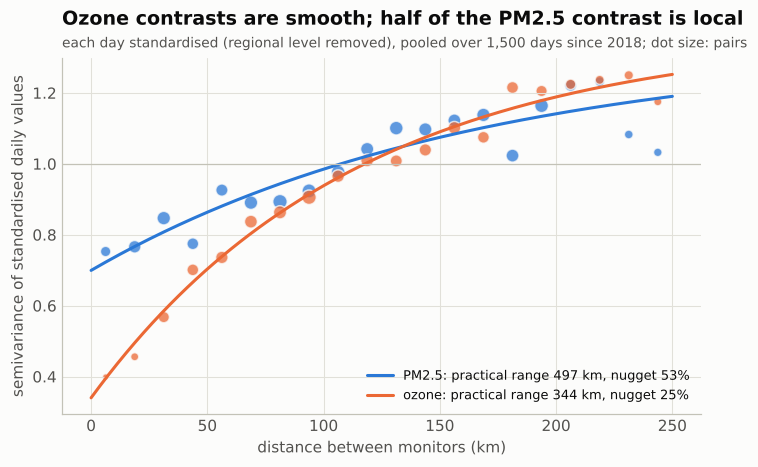

In [3]:
bins = np.arange(0, 260, 12.5)
vg = {}
for name, M, st in [("pm25", PM, st_pm), ("o3", O3, st_o3)]:
    days = M.loc["2018":].dropna(thresh=20).index
    pick = RNG.choice(days, size=min(1500, len(days)), replace=False)
    xy = np.vstack(st.xy)
    emp = sp.empirical_variogram(xy, M.loc[pick].to_numpy(), bins)
    vg[name] = (emp, sp.fit_variogram(emp))
    display(pd.Series(vg[name][1], name=name).round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
hh = np.linspace(0, 250, 200)
for name, color, lab in [("pm25", viz.SERIES[0], "PM2.5"), ("o3", viz.SERIES[1], "ozone")]:
    emp, par = vg[name]
    ax.scatter(emp.h, emp.gamma, s=np.clip(emp.pairs / emp.pairs.max() * 90, 8, 90), color=color, alpha=0.75,
               edgecolor=viz.SURFACE, lw=1)
    ax.plot(hh, sp.exp_variogram(hh, par["nugget"], par["psill"], par["range"]), color=color, lw=2,
            label=f"{lab}: practical range {par['range']:.0f} km, nugget {100 * par['nugget_frac']:.0f}%")
ax.axhline(1, color=viz.AXIS, lw=0.8)
ax.set_xlabel("distance between monitors (km)")
ax.set_ylabel("semivariance of standardised daily values")
viz.title(ax, "Ozone contrasts are smooth; half of the PM2.5 contrast is local",
          "each day standardised (regional level removed), pooled over 1,500 days since 2018; dot size: pairs")
ax.legend(loc="lower right", fontsize=8.5)
viz.save(fig, "03_variograms")
plt.show()

## 3 · Which spatial predictor? A spatial cross-validation benchmark

Monitors are split into 8 groups; each group is hidden in turn and predicted from the
other seven, on 300 random days since 2018 plus the five worst PM2.5 days. Every method
sees exactly the same monitors, so the comparison is fair to the learned methods.

* **nearest monitor** and **network mean** (naive baselines);
* **IDW** (power 2);
* **ordinary kriging** with the pooled variogram above;
* **Gaussian process** (Matern 3/2 + noise), hyperparameters fitted every day;
* **RFSI-LightGBM**: values and distances of the 6 nearest monitors, IDW estimates,
  network statistics, distance to Midtown and to the coast, coordinates and season;
* **kriging + boosted residual**: kriging prediction corrected by LightGBM trained on
  the kriging leave-one-out residuals of the training monitors (a learned "regression
  kriging").

The learned models are trained on all days since 2016, on training monitors only.

In [4]:
N_FOLDS = 8


def spatial_cv(name: str, M: pd.DataFrame, st: pd.DataFrame, eval_days):
    xy = np.vstack(st.xy)
    folds = RNG.permutation(np.arange(M.shape[1]) % N_FOLDS)
    _, par = vg[name]
    rows = []
    for d in eval_days:
        z = M.loc[d].to_numpy()
        for k in range(N_FOLDS):
            te = np.flatnonzero((folds == k) & ~np.isnan(z))
            tr = np.flatnonzero((folds != k) & ~np.isnan(z))
            if len(te) == 0 or len(tr) < 12:
                continue
            a, b, c = xy[tr], z[tr], xy[te]
            preds = {"nearest monitor": b[np.argmin(sp.pairwise(c, a), axis=1)],
                     "network mean": np.full(len(te), b.mean()),
                     "IDW": sp.idw(a, b, c),
                     "ordinary kriging": sp.OrdinaryKriging(par["range"], par["nugget_frac"]).fit(a, b).predict(c),
                     "Gaussian process": sp.make_gp().fit(a, b).predict(c)}
            for j, s_ in enumerate(te):
                rows.append({"date": d, "station": M.columns[s_], "obs": z[s_], **{m: v[j] for m, v in preds.items()}})
    res = pd.DataFrame(rows)
    return res.merge(learned_cv(M, st, eval_days, folds, par), on=["date", "station"], how="left")


def learned_cv(M: pd.DataFrame, st: pd.DataFrame, eval_days, folds, par):
    xy = np.vstack(st.xy)
    lat, lon = st.lat.to_numpy(), st.lon.to_numpy()
    static = np.column_stack([lat, lon, sp.haversine_km(lat, lon, *sp.NYC_CENTER),
                              sp.coast_distance_km(lon, lat, layers)])
    train_days = M.loc["2016":].index
    cal = features.calendar_features(train_days)[["doy_sin", "doy_cos", "dow"]].to_numpy()
    Z = M.loc[train_days].to_numpy()
    ev = np.flatnonzero(np.isin(train_days, eval_days))
    params = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=30, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=4)
    out = []
    for k in range(N_FOLDS):
        test_cols = np.flatnonzero(folds == k)
        Zk = Z.copy()
        Zk[:, test_cols] = np.nan
        ok_feat = np.full(Z.shape, np.nan)       # kriging LOO at training monitors, prediction at test monitors
        for t in range(len(train_days)):
            S = np.flatnonzero(~np.isnan(Zk[t]))
            if len(S) >= 8:
                loo, pr = sp.ok_loo_and_predict(xy[S], Zk[t, S], xy[test_cols], par["range"], par["nugget_frac"])
                ok_feat[t, S], ok_feat[t, test_cols] = loo, pr
        F, names = sp.rfsi_features(Zk, xy, xy, k=6, self_index=np.arange(M.shape[1]))
        T, n, _ = F.shape
        X = np.concatenate([F, np.broadcast_to(static[None], (T, n, static.shape[1])),
                            np.broadcast_to(cal[:, None, :], (T, n, cal.shape[1]))], axis=2)
        Xk = np.concatenate([X, ok_feat[..., None]], axis=2)
        tr = ~np.isnan(Z)
        tr[:, test_cols] = False
        rfsi = lgb.LGBMRegressor(**params).fit(X[tr], Z[tr])
        tr2 = tr & ~np.isnan(ok_feat)
        resid = lgb.LGBMRegressor(**params).fit(Xk[tr2], (Z - ok_feat)[tr2])
        Xe, Xke = X[ev][:, test_cols], Xk[ev][:, test_cols]
        p_rfsi = rfsi.predict(Xe.reshape(-1, X.shape[2])).reshape(len(ev), len(test_cols))
        base = ok_feat[ev][:, test_cols]
        p_hyb = base + resid.predict(Xke.reshape(-1, Xk.shape[2])).reshape(len(ev), len(test_cols))
        for i, t in enumerate(ev):
            for j, c in enumerate(test_cols):
                out.append({"date": train_days[t], "station": M.columns[c], "RFSI-LightGBM": p_rfsi[i, j],
                            "kriging + boosted residual": p_hyb[i, j]})
    return pd.DataFrame(out)


bench = {}
for name, M, st in [("pm25", PM, st_pm), ("o3", O3, st_o3)]:
    cand = M.loc["2018":].dropna(thresh=25).index
    days = list(RNG.choice(cand, size=300, replace=False))
    if name == "pm25":
        days += [d for d in M.loc["2018":].mean(axis=1).nlargest(5).index if d not in days]
    bench[name] = spatial_cv(name, M, st, pd.DatetimeIndex(sorted(days)))
    print(name, "evaluation pairs:", len(bench[name]))

METHODS = ["nearest monitor", "network mean", "IDW", "ordinary kriging", "Gaussian process", "RFSI-LightGBM",
           "kriging + boosted residual"]
rows = []
for name, res in bench.items():
    r_ = res.dropna(subset=METHODS)
    for m in METHODS:
        rows.append({"pollutant": name, "method": m, **fc.regression_scores(r_.obs, r_[m])})
bench_tab = pd.DataFrame(rows)
display(bench_tab.pivot_table(index="method", columns="pollutant", values=["RMSE", "MAE", "R2"]).loc[METHODS].round(3))

pm25 evaluation pairs: 16108


o3 evaluation pairs: 16083


MAE            R2          RMSE       
pollutant                      o3   pm25     o3   pm25     o3   pm25
method                                                              
nearest monitor             3.508  1.884  0.840  0.902  4.929  4.003
network mean                4.375  2.115  0.772  0.836  5.886  5.180
IDW                         3.048  1.666  0.883  0.929  4.216  3.399
ordinary kriging            2.777  1.606  0.903  0.934  3.847  3.295
Gaussian process            2.827  1.606  0.899  0.936  3.923  3.231
RFSI-LightGBM               2.928  1.654  0.893  0.924  4.029  3.519
kriging + boosted residual  2.775  1.623  0.904  0.934  3.825  3.297

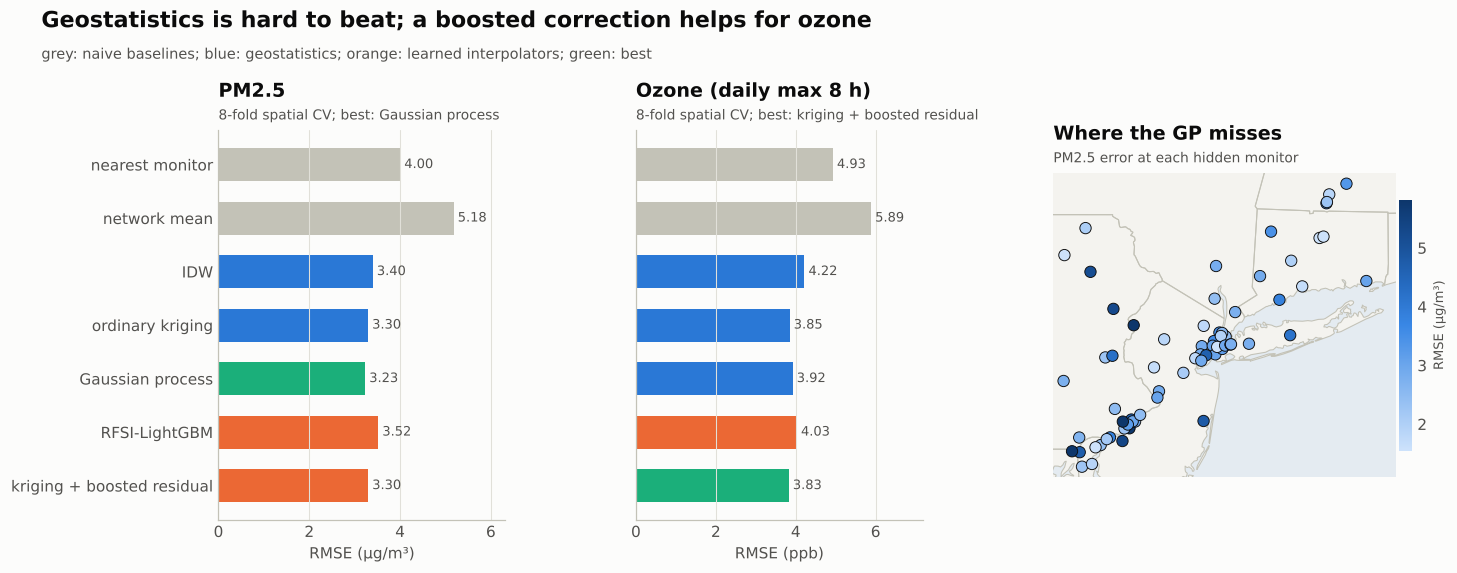

In [5]:
fig = plt.figure(figsize=(14, 4.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.25], wspace=0.42)
for k, (name, unit) in enumerate([("pm25", "\u00b5g/m\u00b3"), ("o3", "ppb")]):
    ax = fig.add_subplot(gs[k])
    t = bench_tab[bench_tab.pollutant == name].set_index("method").loc[METHODS]
    best = t.RMSE.idxmin()
    colors = [viz.CONTEXT] * 2 + [viz.SERIES[0]] * 3 + [viz.SERIES[1]] * 2
    colors = [viz.SERIES[2] if m == best else c for m, c in zip(t.index, colors)]
    ax.barh(range(len(t)), t.RMSE, color=colors, height=0.62)
    for i_, v_ in enumerate(t.RMSE):
        ax.text(v_, i_, f" {v_:.2f}", va="center", fontsize=8.5, color=viz.INK_2)
    ax.set_yticks(range(len(t)), t.index if k == 0 else [""] * len(t))
    ax.invert_yaxis()
    ax.set_xlabel(f"RMSE ({unit})")
    ax.set_xlim(0, t.RMSE.max() * 1.22)
    ax.grid(axis="y", visible=False)
    viz.title(ax, "PM2.5" if name == "pm25" else "Ozone (daily max 8 h)", f"8-fold spatial CV; best: {best}")
ax = fig.add_subplot(gs[2])
res = bench["pm25"]
err = res.groupby("station").apply(lambda g: np.sqrt(np.mean((g["Gaussian process"] - g.obs) ** 2)))
pos = sites.loc[err.index]
viz.draw_basemap(ax, layers, extent=(-76.1, -71.7, 39.45, 42.4), counties=False)
sc = ax.scatter(pos.lon, pos.lat, c=err, cmap=viz.BLUE_CMAP, s=55, edgecolor=viz.INK, lw=0.6, zorder=6,
                norm=Normalize(err.quantile(0.05), err.quantile(0.95)))
cb = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.01)
cb.set_label("RMSE (\u00b5g/m\u00b3)", fontsize=8.5)
cb.outline.set_visible(False)
viz.title(ax, "Where the GP misses", "PM2.5 error at each hidden monitor")
viz.fig_title(fig, "Geostatistics is hard to beat; a boosted correction helps for ozone",
              "grey: naive baselines; blue: geostatistics; orange: learned interpolators; green: best")
viz.save(fig, "03_benchmark")
plt.show()

With tens of monitors and a smooth regional field, the information is in the
neighbours, and geostatistics uses it almost optimally: the Gaussian process wins for
PM2.5. A purely learned interpolator (RFSI) is the weakest of the non-naive methods.
Learning pays when it *corrects* kriging rather than replaces it: for ozone, a
boosted model of the kriging residuals (fed with distance to the urban core and to the
coast) edges ahead, because it captures the titration pattern that a stationary
covariance cannot. The largest errors sit at near-road and edge monitors, whose local
sources no regional interpolator can know.

## 4 · Maps

A 0.01-degree grid (about 1 km) covers the metro area; values over water are masked.
The station-level means are interpolated with the Gaussian process, which also gives the
uncertainty.

grid (130, 250), 21,531 land cells


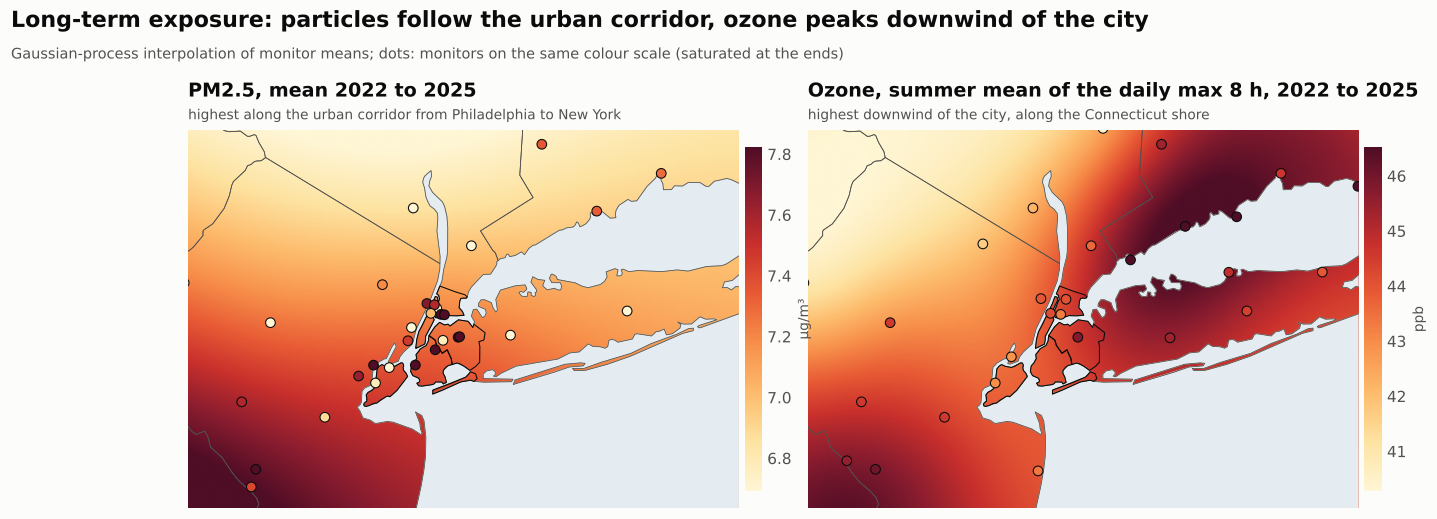

In [6]:
lon_g, lat_g, LON, LAT = sp.make_grid(METRO, 0.01)
LAND = sp.land_mask(LON, LAT, layers)
XY_G = sp.to_xy_km(LAT.ravel(), LON.ravel())
print(f"grid {LON.shape}, {LAND.sum():,} land cells")


def gp_map(values: pd.Series, coords: pd.DataFrame, grid_xy=XY_G, shape=LON.shape):
    v = values.dropna()
    xy = sp.to_xy_km(coords.loc[v.index, "lat"], coords.loc[v.index, "lon"])
    gp = sp.make_gp(length_km=40).fit(xy, v.to_numpy())
    mu, sd = gp.predict(grid_xy, return_std=True)
    return mu.reshape(shape), sd.reshape(shape), gp


def show_field(ax, field, cmap, norm, extent=METRO, boroughs_=True, stations=None, svals=None,
               lon_vec=None, lat_vec=None, levels=None):
    """Raster over land: the field is drawn everywhere, then water is painted on top.
    With ``levels`` the field is drawn as filled contours (smooth category edges)."""
    lon_vec = lon_g if lon_vec is None else lon_vec
    lat_vec = lat_g if lat_vec is None else lat_vec
    viz.draw_basemap(ax, layers, extent=extent, boroughs=False)
    d = (lon_vec[1] - lon_vec[0]) / 2
    if levels is not None:
        LONv, LATv = np.meshgrid(lon_vec, lat_vec)
        im = ax.contourf(LONv, LATv, field, levels=levels, cmap=cmap, norm=norm, zorder=2)
    else:
        im = ax.imshow(field, origin="lower", extent=[lon_vec[0] - d, lon_vec[-1] + d, lat_vec[0] - d,
                                                      lat_vec[-1] + d],
                       cmap=cmap, norm=norm, interpolation="bilinear", zorder=2)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    viz.overlay_water(ax, layers)
    layers["states"].boundary.plot(ax=ax, color=viz.INK_2, lw=0.5, zorder=5)
    if boroughs_:
        boroughs.boundary.plot(ax=ax, color=viz.INK, lw=0.7, zorder=6)
    if stations is not None:
        ax.scatter(stations.lon, stations.lat, c=svals, cmap=cmap, norm=norm, s=40, edgecolor=viz.INK, lw=0.7, zorder=8)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    return im


period = slice("2022-01-01", "2025-12-31")
pm_mean = PM.loc[period].mean().where(PM.loc[period].notna().sum() > 600)
o3_summer = O3.loc[period]
o3_summer = o3_summer[o3_summer.index.month.isin([5, 6, 7, 8, 9])]
o3_mean = o3_summer.mean().where(o3_summer.notna().sum() > 250)
pm_mu, pm_sd, _ = gp_map(pm_mean, sites)
o3_mu, o3_sd, _ = gp_map(o3_mean, sites)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"wspace": 0.08})
norm_pm = Normalize(*np.nanpercentile(pm_mu[LAND], [2, 98]))
im = show_field(axes[0], pm_mu, viz.HEAT_CMAP, norm_pm, stations=sites.loc[pm_mean.dropna().index],
                svals=pm_mean.dropna())
cb = fig.colorbar(im, ax=axes[0], fraction=0.03, pad=0.01)
cb.set_label("µg/m³", fontsize=9)
cb.outline.set_visible(False)
viz.title(axes[0], "PM2.5, mean 2022 to 2025", "highest along the urban corridor from Philadelphia to New York")
norm_o3 = Normalize(*np.nanpercentile(o3_mu[LAND], [2, 98]))
im = show_field(axes[1], o3_mu, viz.HEAT_CMAP, norm_o3, stations=sites.loc[o3_mean.dropna().index],
                svals=o3_mean.dropna())
cb = fig.colorbar(im, ax=axes[1], fraction=0.03, pad=0.01)
cb.set_label("ppb", fontsize=9)
cb.outline.set_visible(False)
viz.title(axes[1], "Ozone, summer mean of the daily max 8 h, 2022 to 2025",
          "highest downwind of the city, along the Connecticut shore")
viz.fig_title(fig, "Long-term exposure: particles follow the urban corridor, ozone peaks downwind of the city",
              "Gaussian-process interpolation of monitor means; dots: monitors on the same colour scale (saturated at "
              "the ends)")
viz.save(fig, "03_longterm_maps")
plt.show()

### 4.1 · The ozone-NO2 mirror

Why is ozone *lower* where traffic is heaviest? Fresh NO emissions destroy ozone
(NO + O3 -> NO2 + O2). The reaction conserves the oxidant Ox = O3 + NO2, so titration
shifts oxidant from O3 to NO2: pure titration would give a slope of -1 between the two.
Using the 2024 hourly sample (one file every 5 hours, so every hour of the day is
represented), the monitors that measure both gases show the trade-off.

,NO2,OZONE,site,state,lat,lon,Ox
full_aqsid,,,,,,,
840340170006,13.3,27.1,Bayonne,NJ,40.7,-74.1,40.4
840090090027,11.2,27.9,New Haven,CT,41.3,-72.9,39.2
840421010048,11.2,28.3,NEW,PA,40.0,-75.1,39.6
840340410007,9.9,21.3,Columbia,NJ,40.9,-75.1,31.2
840090019003,8.5,34.8,Westport,CT,41.1,-73.3,43.2
840340230011,7.3,26.0,Rutgers University,NJ,40.5,-74.4,33.3
840090031003,6.9,27.5,East Hartford,CT,41.8,-72.6,34.3
840361030044,4.1,32.5,Flax Pond,NY,41.0,-73.1,36.7
840250130008,4.0,28.6,Chicopee,MA,42.2,-72.6,32.6


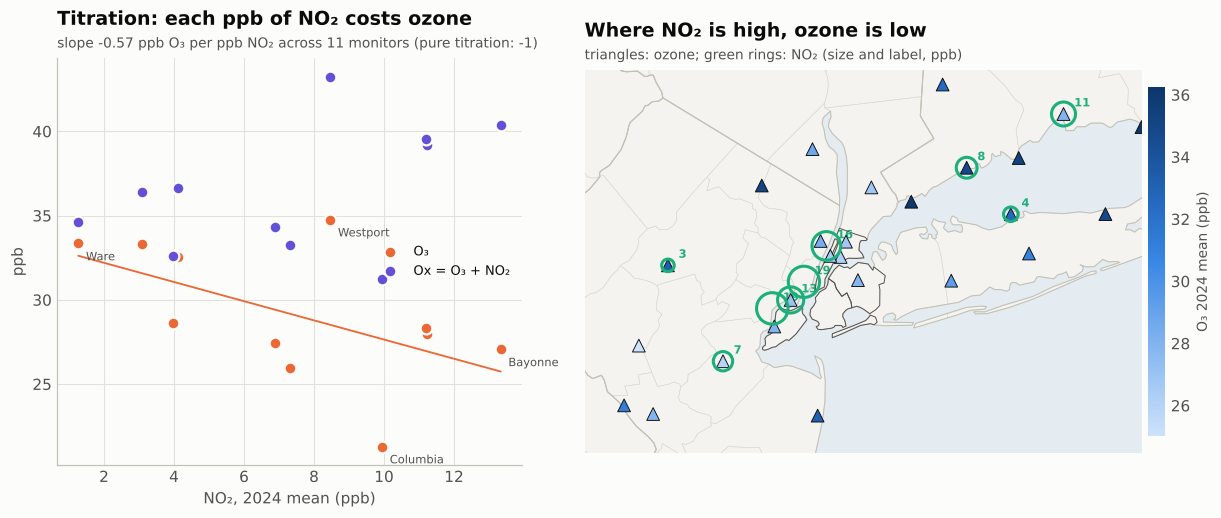

In [7]:
h24, h24s = data.load_airnow_hourly(data.DATA / "airnow" / "airnow_hourly_2024_every5h.csv.gz")
hm = h24.pivot_table(index="full_aqsid", columns="param", values="value", aggfunc="mean")
hn = h24.pivot_table(index="full_aqsid", columns="param", values="value", aggfunc="count")
pair = hm[(hn.get("NO2", 0) > 800) & (hn.get("OZONE", 0) > 800)][["NO2", "OZONE"]].dropna()
pair = pair.join(h24s[["site", "state", "lat", "lon"]])
pair["Ox"] = pair.NO2 + pair.OZONE
slope = np.polyfit(pair.NO2, pair.OZONE, 1)
display(pair.sort_values("NO2", ascending=False).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.12})
ax = axes[0]
ax.scatter(pair.NO2, pair.OZONE, s=60, color=viz.SERIES[1], edgecolor=viz.SURFACE, lw=1.5, zorder=3, label="O₃")
ax.scatter(pair.NO2, pair.Ox, s=60, color=viz.SERIES[6], edgecolor=viz.SURFACE, lw=1.5, zorder=3,
           label="Ox = O₃ + NO₂")
xx = np.linspace(pair.NO2.min(), pair.NO2.max(), 10)
ax.plot(xx, np.polyval(slope, xx), color=viz.SERIES[1], lw=1.2)
for _, r in pair.loc[[pair.NO2.idxmax(), pair.NO2.idxmin(), pair.OZONE.idxmax(), pair.OZONE.idxmin()]].iterrows():
    ax.annotate(r.site, (r.NO2, r.OZONE), xytext=(5, -11), textcoords="offset points", fontsize=7.5,
                color=viz.INK_2)
ax.set_xlabel("NO₂, 2024 mean (ppb)")
ax.set_ylabel("ppb")
viz.title(ax, "Titration: each ppb of NO₂ costs ozone", f"slope {slope[0]:.2f} ppb O₃ per ppb NO₂ across "
          f"{len(pair)} monitors (pure titration: -1)")
ax.legend(loc="center right", fontsize=8.5)
ax = axes[1]
viz.draw_basemap(ax, layers, extent=METRO, boroughs=True)
no2_sites = hm[hn.get("NO2", 0) > 800].NO2.dropna()
no2_sites = h24s.loc[no2_sites.index, ["site", "lat", "lon"]].assign(no2=no2_sites)
no2_sites = no2_sites[no2_sites.lon.between(METRO[0], METRO[1]) & no2_sites.lat.between(METRO[2], METRO[3])]
o3_sites = hm[hn.get("OZONE", 0) > 800].OZONE.dropna()
o3_sites = h24s.loc[o3_sites.index, ["site", "lat", "lon"]].assign(o3=o3_sites)
o3_sites = o3_sites[o3_sites.lon.between(METRO[0], METRO[1]) & o3_sites.lat.between(METRO[2], METRO[3])]
sc = ax.scatter(o3_sites.lon, o3_sites.lat, c=o3_sites.o3, cmap=viz.BLUE_CMAP, s=70, edgecolor=viz.INK, lw=0.6,
                zorder=7, marker="^")
ax.scatter(no2_sites.lon, no2_sites.lat, s=no2_sites.no2 * 22, facecolor="none", edgecolor=viz.SERIES[2], lw=2,
           zorder=8)
for _, r in no2_sites.iterrows():
    ax.annotate(f"{r.no2:.0f}", (r.lon, r.lat), xytext=(7, 5), textcoords="offset points", fontsize=7.5,
                color=viz.SERIES[2], fontweight="bold")
cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.01)
cb.set_label("O₃ 2024 mean (ppb)", fontsize=9)
cb.outline.set_visible(False)
viz.title(ax, "Where NO₂ is high, ozone is low", "triangles: ozone; green rings: NO₂ (size and label, ppb)")
viz.save(fig, "03_titration")
plt.show()

### 4.2 · How many days above the WHO guideline? A probabilistic map

For every day of 2025 a Gaussian process is fitted to the monitors and gives, at each
grid cell, the probability that PM2.5 exceeds the WHO 24-hour guideline (15 ug/m3) or
that ozone exceeds 70 ppb (AQI 101, "Unhealthy for Sensitive Groups"). Summing the
probabilities over the year gives the **expected number of exceedance days** at every
location, monitored or not.

days modelled: PM2.5 365, ozone 183


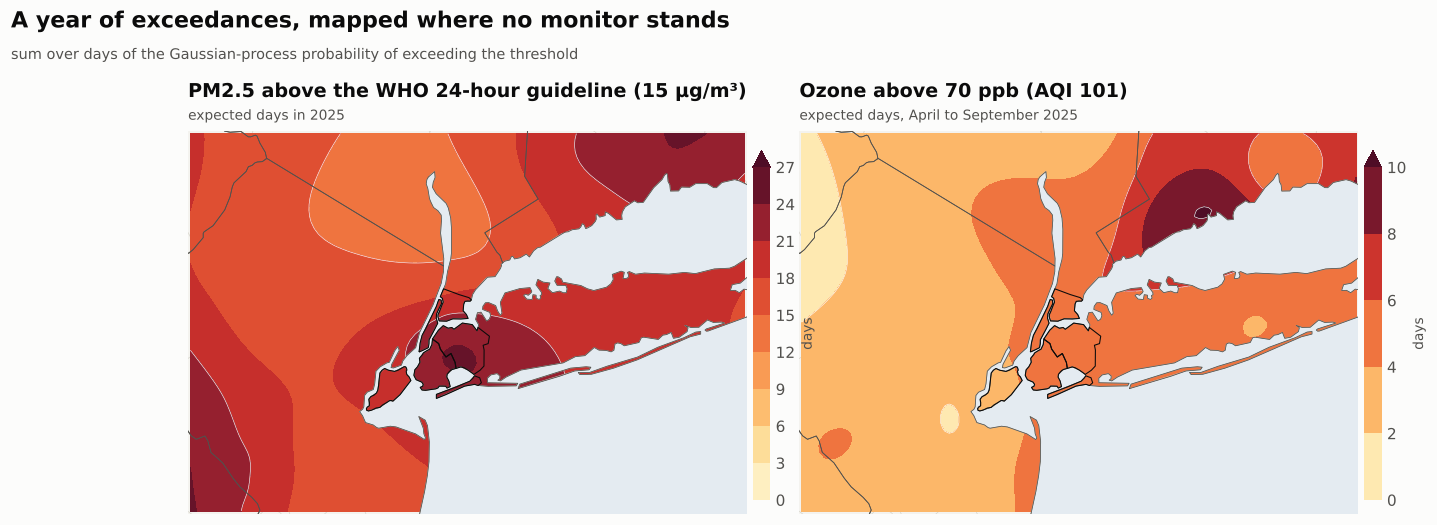

In [8]:
lon_c, lat_c, LONc, LATc = sp.make_grid(METRO, 0.02)
LANDc = sp.land_mask(LONc, LATc, layers)
XYc = sp.to_xy_km(LATc.ravel(), LONc.ravel())


def expected_exceedances(M, year, threshold, months=None):
    total = np.zeros(LONc.size)
    n = 0
    days = M.loc[str(year)].index
    if months:
        days = days[days.month.isin(months)]
    for d in days:
        z = M.loc[d].dropna()
        if len(z) < 15:
            continue
        xy = sp.to_xy_km(sites.loc[z.index, "lat"], sites.loc[z.index, "lon"])
        gp = sp.make_gp(length_km=60).fit(xy, z.to_numpy())
        mu, sd = gp.predict(XYc, return_std=True)
        total += sp.exceedance_probability(mu, sd, threshold)
        n += 1
    return total.reshape(LONc.shape), n


exc_pm, n_pm_days = expected_exceedances(PM, 2025, ix.who_guideline("pm25", "24h"))
exc_o3, n_o3_days = expected_exceedances(O3, 2025, 70.5, months=[4, 5, 6, 7, 8, 9])
print(f"days modelled: PM2.5 {n_pm_days}, ozone {n_o3_days}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"wspace": 0.05})
for ax, field, title_, sub_, vmax in [
        (axes[0], exc_pm, "PM2.5 above the WHO 24-hour guideline (15 µg/m³)", "expected days in 2025", None),
        (axes[1], exc_o3, "Ozone above 70 ppb (AQI 101)", "expected days, April to September 2025", None)]:
    viz.draw_basemap(ax, layers, extent=METRO, boroughs=False)
    top = np.nanpercentile(field[LANDc], 99.5)
    step = max(1, int(np.ceil(top / 9)))
    levels = np.arange(0, top + step, step)
    cs = ax.contourf(LONc, LATc, field, levels=levels, cmap=viz.HEAT_CMAP, zorder=2, extend="max")
    ax.contour(LONc, LATc, field, levels=levels[1::2], colors=viz.SURFACE, linewidths=0.4, zorder=3)
    ax.set_xlim(METRO[0], METRO[1])
    ax.set_ylim(METRO[2], METRO[3])
    viz.overlay_water(ax, layers)
    layers["states"].boundary.plot(ax=ax, color=viz.INK_2, lw=0.5, zorder=5)
    boroughs.boundary.plot(ax=ax, color=viz.INK, lw=0.7, zorder=6)
    ax.set_xlim(METRO[0], METRO[1])
    ax.set_ylim(METRO[2], METRO[3])
    cb = fig.colorbar(cs, ax=ax, fraction=0.03, pad=0.01)
    cb.set_label("days", fontsize=9)
    cb.outline.set_visible(False)
    viz.title(ax, title_, sub_)
viz.fig_title(fig, "A year of exceedances, mapped where no monitor stands",
              "sum over days of the Gaussian-process probability of exceeding the threshold")
viz.save(fig, "03_exceedance_maps")
plt.show()

### 4.3 · The worst day: June 7, 2023

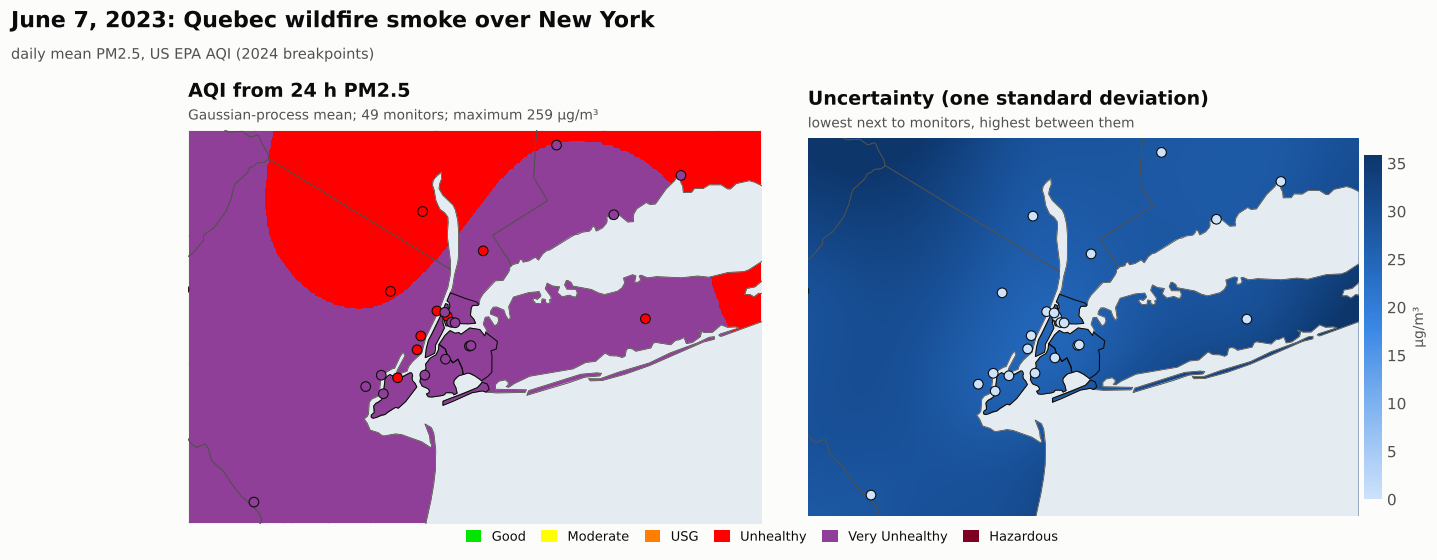

In [9]:
worst = pd.Timestamp("2023-06-07")
z = PM.loc[worst].dropna()
w_mu, w_sd, w_gp = gp_map(z, sites)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw={"wspace": 0.08})
aqi_field = ix.epa_subindex(w_mu, "pm25", round_result=False)
im = show_field(axes[0], aqi_field, viz.AQI_CMAP, viz.AQI_NORM, stations=sites.loc[z.index],
                svals=ix.epa_subindex(z.to_numpy(), "pm25"), levels=viz.AQI_BOUNDS)
viz.aqi_legend(axes[0], bbox=(1.0, -0.08), fontsize=8.5)
viz.title(axes[0], "AQI from 24 h PM2.5", f"Gaussian-process mean; {len(z)} monitors; maximum "
          f"{z.max():.0f} µg/m³")
im = show_field(axes[1], w_sd, viz.BLUE_CMAP, Normalize(0, np.nanpercentile(w_sd[LAND], 98)),
                stations=sites.loc[z.index], svals=np.zeros(len(z)))
cb = fig.colorbar(im, ax=axes[1], fraction=0.03, pad=0.01)
cb.set_label("µg/m³", fontsize=9)
cb.outline.set_visible(False)
viz.title(axes[1], "Uncertainty (one standard deviation)", "lowest next to monitors, highest between them")
viz.fig_title(fig, "June 7, 2023: Quebec wildfire smoke over New York", "daily mean PM2.5, US EPA AQI (2024 breakpoints)")
viz.save(fig, "03_worst_day")
plt.show()

## 5 · The June 2023 smoke plume, hour by hour

AirNow hourly files from June 5 to 9, 2023 (UTC) for about 200 PM2.5 monitors from
Virginia to Quebec. Each hour is interpolated with a Gaussian process on a 0.1-degree
grid and coloured by the AQI category of the instantaneous concentration (the official
AQI uses 24-hour means; hourly values are shown for the dynamics).

120 hourly frames, 204 monitors; peak monitor value 585 ug/m3


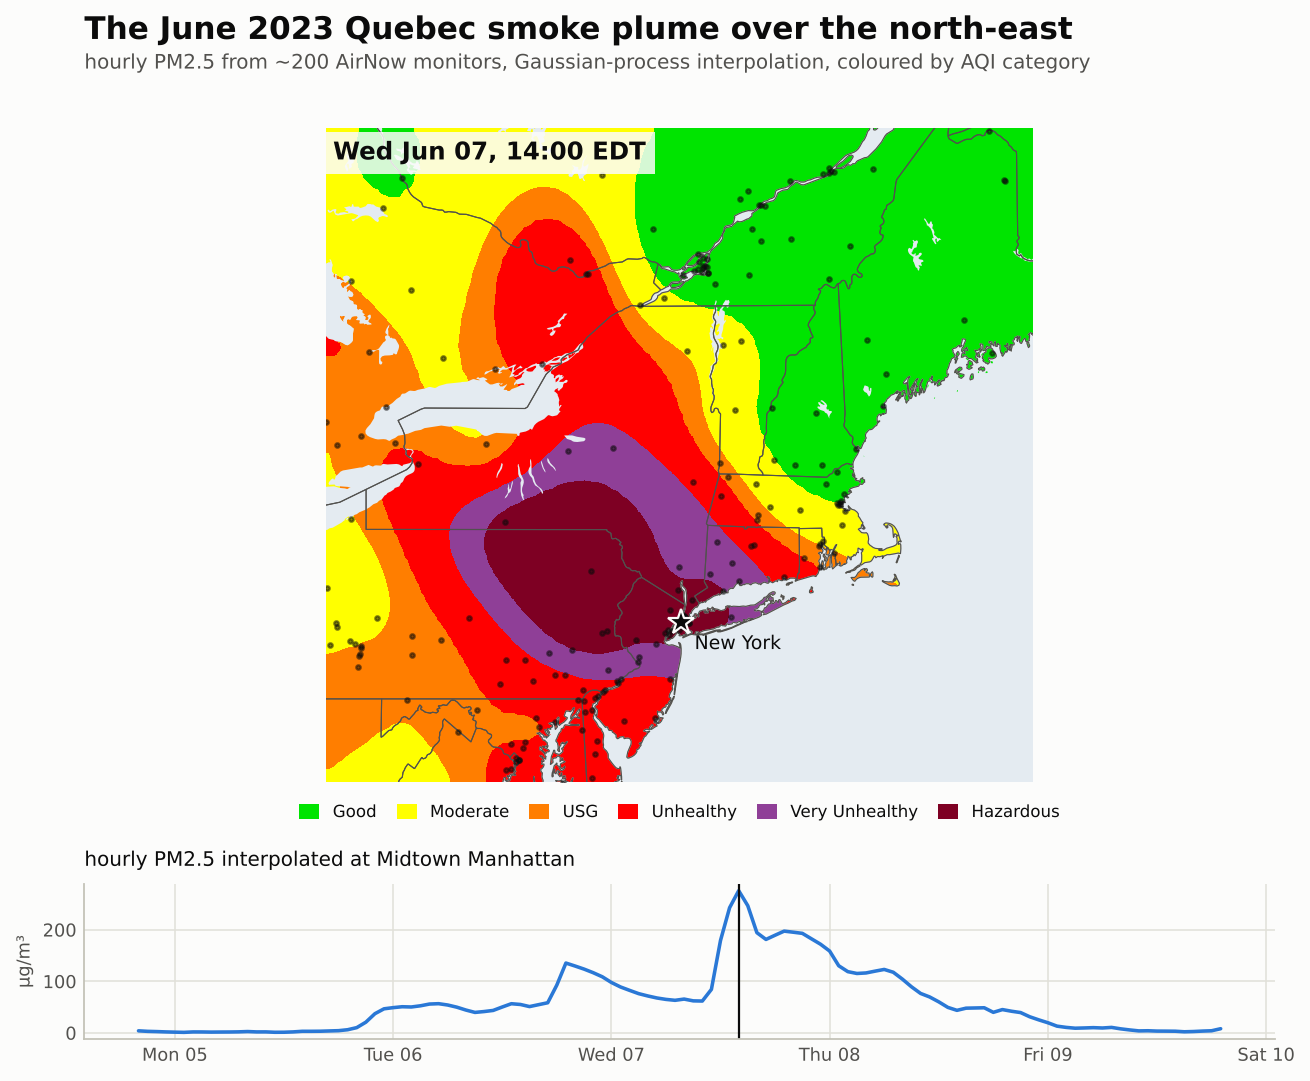

animation written to v2/figures/03_smoke_june2023.gif (1.8 MB)


In [10]:
hs_raw, hs_sites = data.load_airnow_hourly(data.DATA / "airnow" / "airnow_hourly_smoke_2023.csv.gz")
hp = hs_raw[hs_raw.param == "PM2.5"].pivot_table(index="time", columns="full_aqsid", values="value")
hp = hp.loc[:, hp.notna().mean() > 0.6].clip(lower=0)
NE = (-80.5, -67.5, 38.6, 47.4)
lon_n, lat_n, LONn, LATn = sp.make_grid(NE, 0.1)
LANDn = sp.land_mask(LONn, LATn, layers)
XYn = sp.to_xy_km(LATn.ravel(), LONn.ravel(), lat0=43.0, lon0=-74.0)
coords = hs_sites.loc[hp.columns]
xy_n = sp.to_xy_km(coords.lat, coords.lon, lat0=43.0, lon0=-74.0)
frames = []
for t in hp.index:
    z = hp.loc[t].to_numpy()
    ok = ~np.isnan(z)
    gp = sp.make_gp(length_km=120, noise=0.05).fit(xy_n[ok], np.log1p(z[ok]))
    frames.append(np.expm1(gp.predict(XYn)).reshape(LONn.shape))
frames = np.array(frames)
print(f"{len(frames)} hourly frames, {hp.shape[1]} monitors; peak monitor value {np.nanmax(hp.to_numpy()):.0f} ug/m3")

nyc_cell = np.unravel_index(np.argmin(np.abs(LONn - (-73.97)) + np.abs(LATn - 40.75)), LONn.shape)
nyc_series = pd.Series(frames[:, nyc_cell[0], nyc_cell[1]], index=hp.index)

fig = plt.figure(figsize=(9.6, 7.4))
gs = fig.add_gridspec(2, 1, height_ratios=[4.2, 1], hspace=0.25)
ax = fig.add_subplot(gs[0])
viz.draw_basemap(ax, layers, extent=NE, counties=False)
im = ax.imshow(ix.epa_subindex(frames[0], "pm25"), origin="lower",
               extent=[lon_n[0] - 0.05, lon_n[-1] + 0.05, lat_n[0] - 0.05, lat_n[-1] + 0.05], cmap=viz.AQI_CMAP,
               norm=viz.AQI_NORM, interpolation="bilinear", zorder=2)
ax.set_xlim(NE[0], NE[1])
ax.set_ylim(NE[2], NE[3])
viz.overlay_water(ax, layers)
layers["states"].boundary.plot(ax=ax, color=viz.INK_2, lw=0.5, zorder=5)
ax.scatter(coords.lon, coords.lat, s=4, color=viz.INK, alpha=0.5, zorder=6)
ax.plot(-73.97, 40.75, marker="*", ms=12, color=viz.INK, mec=viz.SURFACE, zorder=7)
ax.annotate("New York", (-73.97, 40.75), xytext=(6, -12), textcoords="offset points", fontsize=8.5, zorder=7)
stamp = ax.text(0.01, 0.98, "", transform=ax.transAxes, fontsize=11, fontweight="bold", va="top", zorder=8,
                bbox=dict(fc=viz.SURFACE, ec="none", alpha=0.85))
viz.aqi_legend(ax, loc="upper center", bbox=(0.5, -0.01), fontsize=7.5)
ax2 = fig.add_subplot(gs[1])
local = nyc_series.index.tz_convert("America/New_York")
ax2.plot(local, nyc_series, color=viz.POLLUTANT_COLORS["pm25"], lw=1.6)
cursor = ax2.axvline(local[0], color=viz.INK, lw=1)
ax2.set_ylabel("µg/m³", fontsize=8)
ax2.tick_params(labelsize=8)
import matplotlib.dates as mdates  # noqa: E402
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz="America/New_York"))
ax2.set_title("hourly PM2.5 interpolated at Midtown Manhattan", fontsize=9, fontweight="normal", loc="left")
fig.text(0.125, 0.955, "The June 2023 Quebec smoke plume over the north-east", fontsize=14, fontweight="bold")
fig.text(0.125, 0.93, "hourly PM2.5 from ~200 AirNow monitors, Gaussian-process interpolation, coloured by AQI category",
         fontsize=9, color=viz.INK_2)


def draw(i):
    im.set_data(ix.epa_subindex(frames[i], "pm25"))
    stamp.set_text(local[i].strftime("%a %b %d, %H:%M EDT"))
    cursor.set_xdata([local[i], local[i]])
    return im, stamp, cursor


viz.strip_geo_labels(fig)
anim = animation.FuncAnimation(fig, draw, frames=range(0, len(frames), 2), interval=160, blit=False)
gif_path = data.FIGURES / "03_smoke_june2023.gif"
anim.save(gif_path, writer=animation.PillowWriter(fps=6), dpi=72)
draw(int(np.argmax(nyc_series.to_numpy())))
viz.save(fig, "03_smoke_peak_frame")
plt.close(fig)
display(Image(filename=str(data.FIGURES / "03_smoke_peak_frame.png")))
print(f"animation written to {gif_path.relative_to(data.ROOT)} ({gif_path.stat().st_size / 1e6:.1f} MB)")

### 5.1 · Interactive version

The same episode as an interactive Leaflet map with a time slider (every second hour):
each monitor is a circle coloured by its hourly AQI category (open
`maps/smoke_june2023.html` in a browser).

In [11]:
import folium  # noqa: E402
from folium.plugins import TimestampedGeoJson  # noqa: E402

feats = []
for t in hp.index[::2]:
    row = hp.loc[t].dropna()
    for sid, v in row.items():
        a = float(ix.epa_subindex(v, "pm25"))
        feats.append({"type": "Feature",
                      "geometry": {"type": "Point", "coordinates": [float(coords.lon[sid]), float(coords.lat[sid])]},
                      "properties": {"time": t.strftime("%Y-%m-%dT%H:%M:%SZ"),
                                     "popup": f"{hs_sites.site.get(sid, sid)}<br>{v:.0f} ug/m3, AQI {a:.0f}",
                                     "icon": "circle",
                                     "iconstyle": {"fillColor": viz.aqi_color(a)[0], "fillOpacity": 0.85,
                                                   "stroke": True, "color": "#333333", "weight": 0.6,
                                                   "radius": 6 + min(a, 300) / 40}}})
m = folium.Map(location=[42.5, -74.0], zoom_start=6, tiles="cartodbpositron")
TimestampedGeoJson({"type": "FeatureCollection", "features": feats}, period="PT2H", duration="PT2H",
                   add_last_point=False, auto_play=False, loop=False, max_speed=10, loop_button=True,
                   date_options="YYYY-MM-DD HH:mm UTC", time_slider_drag_update=True).add_to(m)
legend = "".join(f"<div><span style='background:{c.color};width:12px;height:12px;display:inline-block;"
                 f"margin-right:6px;border-radius:2px'></span>{c.name}</div>" for c in ix.EPA_CATEGORIES)
m.get_root().html.add_child(folium.Element(
    "<div style='position:fixed;bottom:30px;left:12px;z-index:9999;background:white;padding:8px 10px;"
    "font:12px system-ui;border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.3)'>"
    f"<b>Hourly PM2.5 AQI, June 5-9, 2023</b>{legend}</div>"))
data.MAPS.mkdir(exist_ok=True)
m.save(data.MAPS / "smoke_june2023.html")
print("saved maps/smoke_june2023.html,", len(feats), "station-hours")

saved maps/smoke_june2023.html, 11936 station-hours


## 6 · Tomorrow's map

A single **global** LightGBM model forecasts the next-day PM2.5 and ozone at every
monitor of the region from: the monitor's own last 3 days, the mean and spread of its 6
nearest neighbours today, the regional mean, weather (regional observations today,
season), and static geography. Quantile objectives with conformal calibration give 80%
intervals. The station forecasts are then interpolated by Gaussian process to a map.

**Validation:** trained on 2018 to 2024, tested on 2025 and 2026 at every monitor.

In [12]:
WX = ["tmax", "tmin", "prcp", "awnd", "wsf2", "gust_u", "gust_v"]


def panel_dataset(M: pd.DataFrame, st: pd.DataFrame, horizon: int = 1, start="2018-01-01"):
    M = M.loc[start:]
    xy = np.vstack(st.xy)
    Z = M.to_numpy()
    F, names = sp.rfsi_features(Z, xy, xy, k=6, self_index=np.arange(M.shape[1]))
    nb = pd.DataFrame({"nn_mean": np.nanmean(F[..., [names.index(f"nn{j}_val") for j in range(1, 7)]], axis=2).ravel(),
                       "net_mean": F[..., names.index("net_mean")].ravel(),
                       "net_std": F[..., names.index("net_std")].ravel(),
                       "mean_50km": F[..., names.index("mean_50km")].ravel()})
    T, n = Z.shape
    df = pd.DataFrame({"date": np.repeat(M.index, n), "station": np.tile(M.columns, T), "y0": Z.ravel()})
    df = pd.concat([df, nb], axis=1)
    lat, lon = st.lat.to_numpy(), st.lon.to_numpy()
    static = pd.DataFrame({"station": M.columns, "lat": lat, "lon": lon,
                           "dist_center": sp.haversine_km(lat, lon, *sp.NYC_CENTER),
                           "dist_coast": sp.coast_distance_km(lon, lat, layers)})
    df = df.merge(static, on="station")
    df = df.sort_values(["station", "date"])
    g = df.groupby("station")
    df["y1"], df["y2"] = g.y0.shift(1), g.y0.shift(2)
    df["target"] = g.y0.shift(-horizon)
    df["target_date"] = df.date + pd.Timedelta(days=horizon)
    df = df.merge(wx[WX].add_suffix("_t0"), left_on="date", right_index=True, how="left")
    cal = features.calendar_features(pd.DatetimeIndex(df.target_date))[["doy_sin", "doy_cos", "dow"]]
    df[cal.columns] = cal.to_numpy()
    return df


FEATS = ["y0", "y1", "y2", "nn_mean", "net_mean", "net_std", "mean_50km", "lat", "lon", "dist_center", "dist_coast",
         "doy_sin", "doy_cos", "dow"] + [f"{w}_t0" for w in WX]
fc_rows, fc_models, fc_preds = [], {}, {}
for name, M, st in [("pm25", PM, st_pm), ("o3", O3, st_o3)]:
    df = panel_dataset(M, st)
    # sorted by date so that the conformal calibration block is the most recent period
    train = df[(df.target_date < "2025-01-01") & df.target.notna() & df.y0.notna()].sort_values("target_date")
    test = df[(df.target_date >= "2025-01-01") & df.target.notna() & df.y0.notna()]
    qb = fc.QuantileBooster(alpha=0.2, params={"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 63,
                                               "min_child_samples": 40})
    qb.fit(train[FEATS].reset_index(drop=True), train.target.reset_index(drop=True))
    p = qb.predict(test[FEATS].reset_index(drop=True))
    p.index = test.index
    test = test.join(p)
    fc_models[name], fc_preds[name] = qb, test
    m_, pers = fc.regression_scores(test.target, test["median"]), fc.regression_scores(test.target, test.y0)
    cov = fc.interval_scores(test.target, test.lo, test.hi, 0.2)["coverage"]
    fc_rows.append({"pollutant": name, "station-days": len(test), "MAE": m_["MAE"], "MAE persistence": pers["MAE"],
                    "skill vs persistence": fc.skill(m_["MAE"], pers["MAE"]), "R2": m_["R2"],
                    "coverage 80%": cov})
display(pd.DataFrame(fc_rows).round(3))

,pollutant,station-days,MAE,MAE persistence,skill vs persistence,R2,coverage 80%
0,pm25,39533,2.546,3.030,0.160,0.474,0.795
1,o3,34226,6.404,7.751,0.174,0.465,0.810


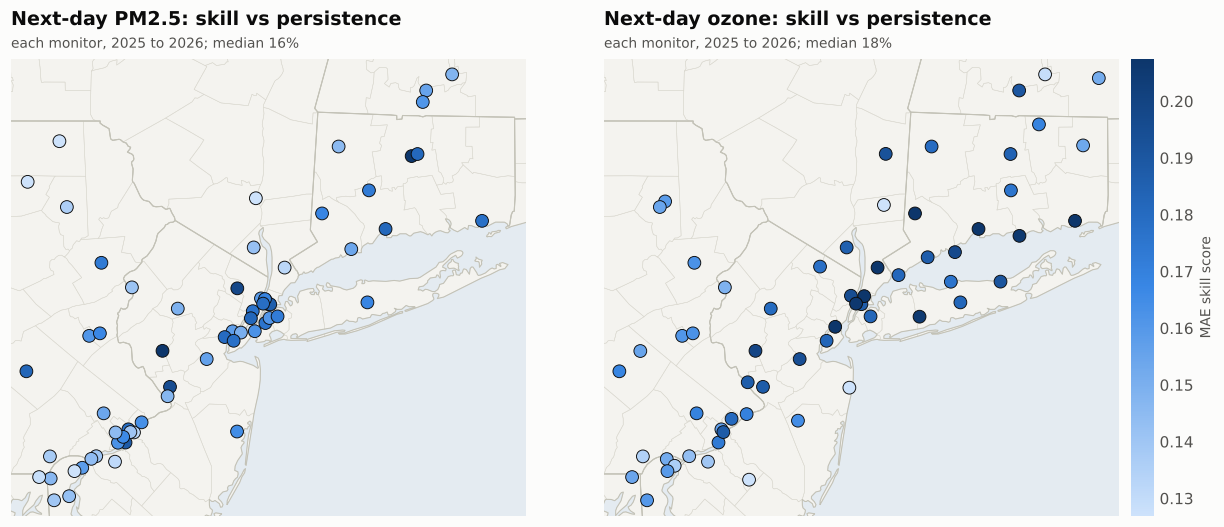

In [13]:
per_station = {}
for name in ["pm25", "o3"]:
    t = fc_preds[name]
    per_station[name] = t.groupby("station").apply(
        lambda g: 1 - np.mean(np.abs(g["median"] - g.target)) / np.mean(np.abs(g.y0 - g.target)) if len(g) > 100
        else np.nan).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"wspace": 0.05})
all_skill = pd.concat(per_station.values())
div = Normalize(*all_skill.quantile([0.05, 0.95]).to_numpy())
for ax, name, lab in [(axes[0], "pm25", "PM2.5"), (axes[1], "o3", "ozone")]:
    viz.draw_basemap(ax, layers, extent=(-76.1, -71.7, 39.45, 42.4))
    s = per_station[name]
    pos = sites.loc[s.index]
    sc = ax.scatter(pos.lon, pos.lat, c=s, cmap=viz.BLUE_CMAP, norm=div, s=70, edgecolor=viz.INK, lw=0.6, zorder=6)
    viz.title(ax, f"Next-day {lab}: skill vs persistence", f"each monitor, 2025 to 2026; median {100 * s.median():.0f}%")
cb = fig.colorbar(sc, ax=axes, fraction=0.02, pad=0.01)
cb.set_label("MAE skill score", fontsize=9)
cb.outline.set_visible(False)
viz.save(fig, "03_forecast_skill_map")
plt.show()

### 6.1 · Live forecast map

forecast for Saturday October 24, 2026: AQI range over land 34 to 55; upper 80% bound up to 63; dominant pollutant over most of the area: PM2.5


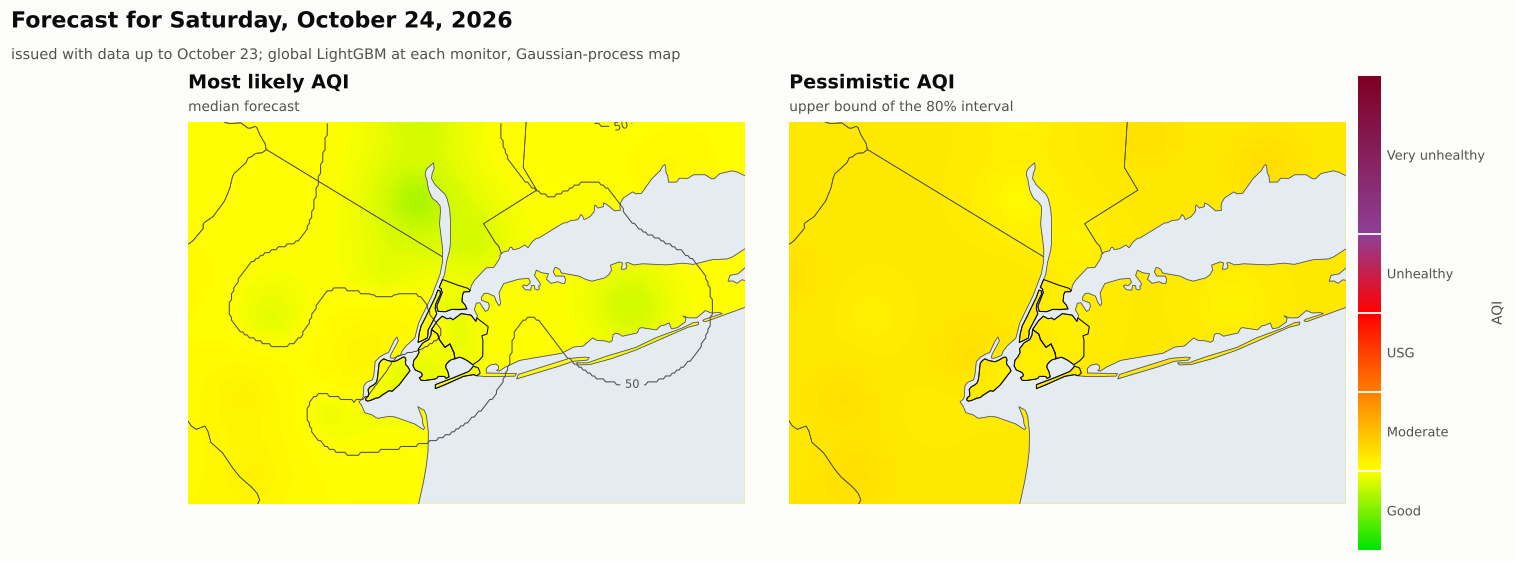

In [14]:
live = {}
for name, M, st in [("pm25", PM, st_pm), ("o3", O3, st_o3)]:
    df = panel_dataset(M, st, start=str(LAST_DAY - pd.Timedelta(days=10))[:10])
    today = df[(df.date == LAST_DAY) & df.y0.notna()]
    p = fc_models[name].predict(today[FEATS].reset_index(drop=True))
    p.index = today.station.to_numpy()
    live[name] = p
target_day = LAST_DAY + pd.Timedelta(days=1)
pm_live, _, _ = gp_map(live["pm25"]["median"], sites)
o3_live, _, _ = gp_map(live["o3"]["median"], sites)
pm_hi, _, _ = gp_map(live["pm25"]["hi"], sites)
o3_hi, _, _ = gp_map(live["o3"]["hi"], sites)
aqi_live = np.fmax(ix.epa_subindex(pm_live, "pm25", round_result=False),
                   ix.epa_subindex(o3_live, "o3_8h", round_result=False))
aqi_hi = np.fmax(ix.epa_subindex(pm_hi, "pm25", round_result=False), ix.epa_subindex(o3_hi, "o3_8h", round_result=False))
dominant = np.where(ix.epa_subindex(pm_live, "pm25") >= ix.epa_subindex(o3_live, "o3_8h"), "PM2.5", "ozone")
print(f"forecast for {target_day:%A %B %d, %Y}: AQI range over land {np.nanmin(aqi_live[LAND]):.0f} to "
      f"{np.nanmax(aqi_live[LAND]):.0f}; upper 80% bound up to {np.nanmax(aqi_hi[LAND]):.0f}; "
      f"dominant pollutant over most of the area: {pd.Series(dominant[LAND]).mode()[0]}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"wspace": 0.08})
aqi_norm = Normalize(0, 300)  # the AQI ramp is anchored on the official colours over 0-300
for ax, field, ttl, sub_ in [(axes[0], aqi_live, "Most likely AQI", "median forecast"),
                             (axes[1], aqi_hi, "Pessimistic AQI", "upper bound of the 80% interval")]:
    im = show_field(ax, field, viz.AQI_CONT_CMAP, aqi_norm)
    cs = ax.contour(LON, LAT, field, levels=[25, 50, 75, 100], colors=viz.INK_2, linewidths=0.7, zorder=4.5)
    ax.clabel(cs, fontsize=7.5, fmt="%d")
    viz.title(ax, ttl, sub_)
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, ticks=[25, 75, 125, 175, 250])
cb.ax.set_yticklabels(["Good", "Moderate", "USG", "Unhealthy", "Very unhealthy"], fontsize=8.5)
for b_ in (50, 100, 150, 200):
    cb.ax.axhline(b_, color=viz.SURFACE, lw=1.2)
cb.set_label("AQI", fontsize=9)
cb.outline.set_visible(False)
viz.fig_title(fig, f"Forecast for {target_day:%A, %B %d, %Y}",
              f"issued with data up to {LAST_DAY:%B %d}; global LightGBM at each monitor, Gaussian-process map")
viz.save(fig, "03_live_forecast_map")
plt.show()

## 7 · Exposure by borough

Daily Gaussian-process maps of 2025 averaged inside each borough, then weighted by the
2020 Census population: who breathes what, and how many **person-days** above the WHO
PM2.5 guideline the city accumulated.

,mean PM2.5 2025,days > 15 ug/m3,population 2020,person-days > WHO (millions)
Brooklyn,7.20,22,2736074,60.19
Queens,7.20,21,2405464,50.51
Manhattan,7.05,19,1694251,32.19
Staten Island,6.97,18,495747,8.92
Bronx,6.92,14,1472654,20.62


population-weighted PM2.5 2025: 7.11 ug/m3 (1.4 x the WHO annual guideline of 5 ug/m3)


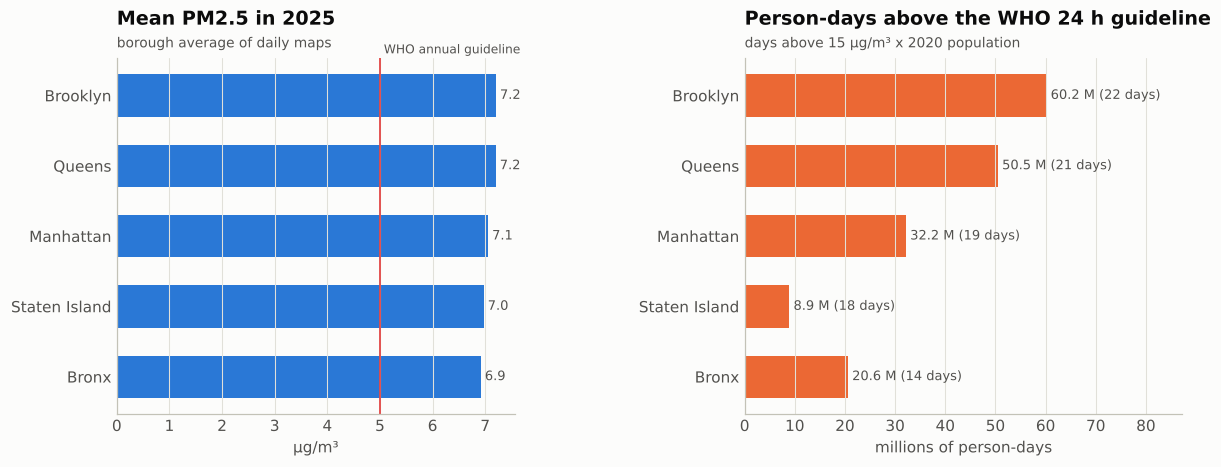

In [15]:
lon_b, lat_b, LONb, LATb = sp.make_grid(CITY, 0.005)
XYb = sp.to_xy_km(LATb.ravel(), LONb.ravel())
inside = {b.borough: __import__("shapely").contains_xy(b.geometry, LONb.ravel(), LATb.ravel())
          for _, b in boroughs.iterrows()}
rows = []
for d in PM.loc["2025"].index:
    z = PM.loc[d].dropna()
    if len(z) < 15:
        continue
    xy = sp.to_xy_km(sites.loc[z.index, "lat"], sites.loc[z.index, "lon"])
    mu = sp.make_gp(length_km=60).fit(xy, z.to_numpy()).predict(XYb)
    rows.append({"date": d, **{b: mu[msk].mean() for b, msk in inside.items()}})
bor = pd.DataFrame(rows).set_index("date")
pop = boroughs.set_index("borough").population_2020
summary = pd.DataFrame({"mean PM2.5 2025": bor.mean(), "days > 15 ug/m3": (bor > 15).sum(),
                        "population 2020": pop})
summary["person-days > WHO (millions)"] = summary["days > 15 ug/m3"] * summary["population 2020"] / 1e6
city_mean = float(np.average(summary["mean PM2.5 2025"], weights=summary["population 2020"]))
display(summary.sort_values("mean PM2.5 2025", ascending=False).round(2))
print(f"population-weighted PM2.5 2025: {city_mean:.2f} ug/m3 "
      f"({city_mean / ix.who_guideline('pm25', 'annual'):.1f} x the WHO annual guideline of 5 ug/m3)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.1], "wspace": 0.55})
s = summary.sort_values("mean PM2.5 2025")
ax = axes[0]
ax.barh(s.index, s["mean PM2.5 2025"], color=viz.SERIES[0], height=0.6)
ax.axvline(ix.who_guideline("pm25", "annual"), color=viz.SERIES[7], lw=1.2)
ax.text(ix.who_guideline("pm25", "annual"), len(s) - 0.4, " WHO annual guideline", color=viz.INK_2, fontsize=8)
for i_, v_ in enumerate(s["mean PM2.5 2025"]):
    ax.text(v_, i_, f" {v_:.1f}", va="center", fontsize=8.5, color=viz.INK_2)
ax.set_xlabel("µg/m³")
ax.grid(axis="y", visible=False)
viz.title(ax, "Mean PM2.5 in 2025", "borough average of daily maps")
ax = axes[1]
ax.barh(s.index, s["person-days > WHO (millions)"], color=viz.SERIES[1], height=0.6)
for i_, (v_, dd) in enumerate(zip(s["person-days > WHO (millions)"], s["days > 15 ug/m3"])):
    ax.text(v_, i_, f" {v_:.1f} M ({dd} days)", va="center", fontsize=8.5, color=viz.INK_2)
ax.set_xlabel("millions of person-days")
ax.set_xlim(0, s["person-days > WHO (millions)"].max() * 1.45)
ax.grid(axis="y", visible=False)
viz.title(ax, "Person-days above the WHO 24 h guideline", "days above 15 µg/m³ x 2020 population")
viz.save(fig, "03_borough_exposure")
plt.show()

## 8 · Interactive exposure map

All the layers in one Leaflet map (`maps/nyc_air_quality_map.html`): long-term PM2.5 and
ozone surfaces, expected WHO exceedance days, tomorrow's forecast, monitors with their
statistics, and borough summaries.

In [16]:
import base64  # noqa: E402
import io  # noqa: E402


def png_overlay(field, cmap, norm, mask, lon_vec, lat_vec):
    rgba = cmap(norm(np.where(mask, field, np.nan)))
    rgba[..., 3] = np.where(mask & ~np.isnan(field), 0.78, 0)
    buf = io.BytesIO()
    plt.imsave(buf, rgba[::-1], format="png")
    url = "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()
    bounds = [[lat_vec[0], lon_vec[0]], [lat_vec[-1], lon_vec[-1]]]
    return url, bounds


m = folium.Map(location=[40.75, -73.95], zoom_start=9, tiles="cartodbpositron", control_scale=True)
for label, field, cmap, norm_, mask_, lv, la, show in [
        ("PM2.5 mean 2022-2025", pm_mu, viz.HEAT_CMAP, norm_pm, LAND, lon_g, lat_g, True),
        ("Ozone summer mean 2022-2025", o3_mu, viz.HEAT_CMAP, norm_o3, LAND, lon_g, lat_g, False),
        ("Expected days PM2.5 > WHO, 2025", exc_pm, viz.HEAT_CMAP, Normalize(0, np.nanpercentile(exc_pm[LANDc], 99)),
         LANDc, lon_c, lat_c, False),
        (f"Forecast AQI {target_day:%Y-%m-%d}", aqi_live, viz.AQI_CONT_CMAP, aqi_norm, LAND, lon_g, lat_g, False)]:
    url, bounds = png_overlay(field, cmap, norm_, mask_, lv, la)
    folium.raster_layers.ImageOverlay(url, bounds=bounds, name=label, show=show, opacity=0.85).add_to(m)
fg = folium.FeatureGroup(name="Monitors (PM2.5 2022-2025 mean)")
for sid, v in pm_mean.dropna().items():
    r = sites.loc[sid]
    folium.CircleMarker([r.lat, r.lon], radius=6, color="#222222", weight=0.8, fill=True,
                        fill_color=viz.aqi_color(ix.epa_subindex(v, "pm25"))[0], fill_opacity=0.95,
                        popup=folium.Popup(f"<b>{r.site}</b> ({r.state})<br>PM2.5 mean 2022-2025: {v:.1f} ug/m3<br>"
                                           f"ozone summer mean: {o3_mean.get(sid, np.nan):.1f} ppb", max_width=260)
                        ).add_to(fg)
fg.add_to(m)
bj = boroughs.merge(summary.reset_index().rename(columns={"index": "borough"}), on="borough")
folium.GeoJson(bj.to_json(), name="Boroughs (2025 summary)",
               style_function=lambda f: {"fillOpacity": 0, "color": "#333333", "weight": 1.2},
               tooltip=folium.GeoJsonTooltip(fields=["borough", "mean PM2.5 2025", "days > 15 ug/m3",
                                                     "population 2020"],
                                             aliases=["Borough", "Mean PM2.5 2025", "Days above WHO", "Population"],
                                             localize=True)).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save(data.MAPS / "nyc_air_quality_map.html")
print("saved maps/nyc_air_quality_map.html")

saved maps/nyc_air_quality_map.html


## 9 · Take-aways

* PM2.5 and ozone are regional pollutants whose contrasts extend over hundreds of km,
  so 60 monitors can map them; NO2 is local and needs the dense street-level surveys
  that AirNow lacks.
* Under a fair spatial cross-validation, geostatistics remains the reference: the
  Gaussian process is the best PM2.5 interpolator, and kriging corrected by a boosted
  residual model is the best for ozone. A purely learned interpolator does not beat them.
* The maps show the two faces of urban air: particles peak in and around the urban
  core, ozone peaks downwind because fresh NO emissions titrate it in the core.
* Probabilistic maps turn sparse monitors into an expected number of exceedance days
  at every address, and population weighting turns them into person-days of exposure.
* The smoke animation shows why local models miss smoke onsets: the plume is visible
  hundreds of km upstream a day before it reaches the city.

## 10 · Key results

Saved to `data/processed/results_03.json` for the report.

In [17]:
import json  # noqa: E402

bt = bench_tab.set_index(["pollutant", "method"])
best_oz = bt.loc["o3"].RMSE.idxmin()
res03 = {
    "n_pm": int(PM.shape[1]), "n_o3": int(O3.shape[1]),
    "vg_pm_nugget": round(100 * vg["pm25"][1]["nugget_frac"]), "vg_o3_nugget": round(100 * vg["o3"][1]["nugget_frac"]),
    "geo_pm_gp_rmse": round(float(bt.loc[("pm25", "Gaussian process"), "RMSE"]), 2),
    "geo_pm_gp_r2": round(float(bt.loc[("pm25", "Gaussian process"), "R2"]), 3),
    "geo_pm_best": bt.loc["pm25"].RMSE.idxmin(), "geo_oz_best": best_oz,
    "geo_oz_best_rmse": round(float(bt.loc[("o3", best_oz), "RMSE"]), 2),
    "geo_oz_best_r2": round(float(bt.loc[("o3", best_oz), "R2"]), 3),
    "geo_rfsi_pm_rmse": round(float(bt.loc[("pm25", "RFSI-LightGBM"), "RMSE"]), 2),
    "pop_pm": round(city_mean, 2), "pop_ratio": round(city_mean / ix.who_guideline("pm25", "annual"), 1),
    "panel_fc": {r_["pollutant"]: {k: round(float(v), 3) for k, v in r_.items() if k != "pollutant"} for r_ in fc_rows},
    "boroughs": {b: {"pm": round(float(row["mean PM2.5 2025"]), 2), "days": int(row["days > 15 ug/m3"]),
                     "person_days_m": round(float(row["person-days > WHO (millions)"]), 1)}
                 for b, row in summary.iterrows()},
    "live_target_day": f"{target_day:%Y-%m-%d}", "live_aqi_min": int(np.nanmin(aqi_live[LAND])),
    "live_aqi_max": int(np.nanmax(aqi_live[LAND])),
}
(data.DATA / "processed" / "results_03.json").write_text(json.dumps(res03, indent=1))
display(pd.Series({k: v for k, v in res03.items() if not isinstance(v, dict)}))

n_pm                                        74
n_o3                                        68
vg_pm_nugget                                53
vg_o3_nugget                                25
geo_pm_gp_rmse                            3.23
geo_pm_gp_r2                             0.936
geo_pm_best                   Gaussian process
geo_oz_best         kriging + boosted residual
geo_oz_best_rmse                          3.83
geo_oz_best_r2                           0.904
geo_rfsi_pm_rmse                          3.52
pop_pm                                    7.11
pop_ratio                                  1.4
live_target_day                     2026-10-24
live_aqi_min                                33
live_aqi_max                                55
dtype: object